# 08 — Cross-Encoder Reranking Evaluation

Cette étape prend les 50 candidats du retrieval `Both` sélectionné à l'étape 7 et les reclasse avec un cross-encoder local. Le test reste verrouillé. La décision de production est mesurée : le reranker n'est accepté que s'il améliore Recall@5 d'au moins 0,5 point sans dégrader MRR@10.

## 1. Contrat expérimental

- Entrée : top-50 Hybrid Original+Rewrite de validation.
- Query du reranker : rewrite conditionnel si le gate est actif, sinon requête originale.
- Passage : titre répété + fenêtres tokenizer-aware chevauchantes du chunk.
- Sortie : le même ensemble de 50 candidats, uniquement réordonné.
- Cache : une clé immuable par `(modèle, révision, query, chunk, représentation, max_length)`.
- Sélection : Recall@5, puis garde-fou MRR@10.
- Test : jamais chargé dans ce notebook.

In [1]:
%pip install -q "torch>=2.2,<3" "transformers>=4.44,<5" "safetensors>=0.4" "psutil>=5.9" numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from __future__ import annotations

import gc
import hashlib
import json
import math
import platform
import sqlite3
import time
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable, Iterator, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import transformers
from IPython.display import display
from transformers import AutoModelForSequenceClassification, AutoTokenizer

pd.set_option("display.max_columns", 160)
pd.set_option("display.max_colwidth", 180)
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
DATASET_ROOT = PROJECT_ROOT / "data" / "processed" / "multidoc2dial_v1"
CONFIG_PATH = PROJECT_ROOT / "configs" / "reranking_experiments.json"
print(f"Project root : {PROJECT_ROOT}")
print(f"Python/Torch/Transformers : {platform.python_version()} / {torch.__version__} / {transformers.__version__}")

Project root : C:\Users\dhiar\OneDrive\Bureau\Project\RAG Assistant
Python/Torch/Transformers : 3.12.7 / 2.5.1+cu121 / 4.57.1


In [3]:
def load_json(path: Path) -> dict[str, Any]:
    value = json.loads(path.read_text(encoding="utf-8"))
    if not isinstance(value, dict): raise TypeError(f"La racine de {path} doit être un objet JSON")
    return value

def iter_jsonl(path: Path) -> Iterator[dict[str, Any]]:
    with path.open(encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, 1):
            try: yield json.loads(line)
            except json.JSONDecodeError as error: raise ValueError(f"JSONL invalide : {path}, ligne {line_number}") from error

def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while block := handle.read(1024 * 1024): digest.update(block)
    return digest.hexdigest()

def text_sha256(text: str) -> str:
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

def stable_hash(value: Any) -> str:
    payload = json.dumps(value, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()

def write_json_atomic(path: Path, value: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    temporary.replace(path)

def write_jsonl_atomic(path: Path, records: Iterable[dict[str, Any]]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w", encoding="utf-8", newline="\n") as handle:
        for record in records: handle.write(json.dumps(record, ensure_ascii=False, separators=(",", ":")) + "\n")
    temporary.replace(path)

def artifact_metadata(path: Path, records: int | None = None) -> dict[str, Any]:
    result = {"path": str(path.relative_to(PROJECT_ROOT)), "bytes": path.stat().st_size, "sha256": file_sha256(path)}
    if records is not None: result["records"] = records
    return result

def dataframe_records(frame: pd.DataFrame) -> list[dict[str, Any]]:
    return json.loads(frame.to_json(orient="records", double_precision=12))

## 2. Chargement et validation des contrats

Chaque artefact entrant est vérifié par son SHA-256. Le notebook charge uniquement `validation/direct_user_response`; le fichier test n'est jamais ouvert.

In [4]:
config = load_json(CONFIG_PATH)
config_hash = stable_hash(config)
assert config["evaluation_split"] == "validation" and "test" in config["locked_splits"]
strategy = config["strategy"]
candidate_depth = config["candidate_depth"]

benchmark_root = DATASET_ROOT / "retrieval_benchmarks" / config["benchmark_id"]
benchmark_manifest_path = benchmark_root / "manifest.json"
benchmark_manifest = load_json(benchmark_manifest_path)
validation_path = benchmark_root / "validation.jsonl"
validation_expected = benchmark_manifest["outputs"]["validation.jsonl"]
assert file_sha256(validation_path) == validation_expected["sha256"]
validation_all = list(iter_jsonl(validation_path))
validation_examples = [item for item in validation_all if item["cohort"] == config["cohort"]]
assert all(item["split"] == "validation" for item in validation_examples)

query_root = DATASET_ROOT / "query_rewriting_experiments" / config["query_rewriting_experiment_id"]
query_manifest_path = query_root / "manifest.json"
query_manifest = load_json(query_manifest_path)
assert query_manifest["quality"]["status"] == "passed" and query_manifest["quality"]["test_split_loaded"] is False
assert query_manifest["selected_mode"] == "Both"
ranking_path = query_root / "rankings" / "selected_mode_validation.jsonl"
rewrite_path = query_root / "rewrites" / "validation_rewrites.jsonl"
assert file_sha256(ranking_path) == query_manifest["artifacts"]["rankings"]["sha256"]
assert file_sha256(rewrite_path) == query_manifest["artifacts"]["rewrites"]["sha256"]
ranking_records = list(iter_jsonl(ranking_path))
rewrite_records = list(iter_jsonl(rewrite_path))

chunk_root = DATASET_ROOT / "chunking_experiments" / config["chunking_experiment_id"] / strategy
chunk_manifest_path = chunk_root / "manifest.json"
chunk_manifest = load_json(chunk_manifest_path)
chunk_path = chunk_root / "chunks.jsonl"
assert chunk_manifest["quality"]["status"] == "passed"
assert file_sha256(chunk_path) == chunk_manifest["outputs"]["chunks.jsonl"]["sha256"]
chunks = list(iter_jsonl(chunk_path))
chunks_by_id = {item["id"]: item for item in chunks}

example_ids = [item["id"] for item in validation_examples]
ranking_by_example = {item["example_id"]: item for item in ranking_records}
rewrite_by_example = {item["example_id"]: item for item in rewrite_records}
assert len(example_ids) == len(set(example_ids)) == len(ranking_by_example) == len(rewrite_by_example)
assert set(example_ids) == set(ranking_by_example) == set(rewrite_by_example)
assert all(len(ranking_by_example[key]["candidates"]) >= candidate_depth for key in example_ids)
assert all(candidate["chunk_id"] in chunks_by_id for key in example_ids for candidate in ranking_by_example[key]["candidates"][:candidate_depth])

experiment_fingerprint = stable_hash({"config": config, "benchmark_manifest": file_sha256(benchmark_manifest_path), "validation": validation_expected["sha256"], "query_manifest": file_sha256(query_manifest_path), "chunks": file_sha256(chunk_path)})
experiment_id = f"{config['experiment_name']}_{experiment_fingerprint[:10]}"
OUTPUT_ROOT = DATASET_ROOT / "reranking_experiments" / experiment_id
REPORT_ROOT = PROJECT_ROOT / "reports" / "generated" / "multidoc2dial_v1" / "reranking_experiments" / experiment_id
RUNTIME_PATH = OUTPUT_ROOT / "runtime_observation.json"
print(f"Validation primaire : {len(validation_examples):,}")
print(f"Candidats par requête : {candidate_depth}")
print(f"Paires brutes : {len(validation_examples) * candidate_depth:,}")
print(f"Test chargé : {False}")
print(f"Experiment ID : {experiment_id}")

Validation primaire : 4,427
Candidats par requête : 50
Paires brutes : 221,350
Test chargé : False
Experiment ID : cross_encoder_reranking_v1_6e405e9926


## 3. Représentations, déduplication et audit de troncature

Le cross-encoder préserve toujours la query. Un chunk trop long est découpé en fenêtres chevauchantes qui respectent `max_length`; le score du chunk est le maximum des logits de ses fenêtres. L'audit est calculé avant l'inférence et sera conservé dans le rapport.

In [5]:
model_config = config["model"]
tokenizer = AutoTokenizer.from_pretrained(model_config["model_id"], revision=model_config["revision"], trust_remote_code=model_config["trust_remote_code"])

def query_for_example(example_id: str) -> str:
    record = rewrite_by_example[example_id]
    query = record["rewritten_query"] if record["gated"] else record["original_query"]
    assert query and isinstance(query, str)
    return query

queries_by_example = {key: query_for_example(key) for key in example_ids}
unique_queries = sorted(set(queries_by_example.values()))
query_lengths_list = tokenizer(unique_queries, add_special_tokens=False, truncation=False, verbose=False)["input_ids"]
query_token_count = {text: len(ids) for text, ids in zip(unique_queries, query_lengths_list)}
chunk_ids_ordered = sorted(chunks_by_id)
content_token_ids_list = tokenizer([chunks_by_id[key]["content"] for key in chunk_ids_ordered], add_special_tokens=False, truncation=False, verbose=False)["input_ids"]
content_token_ids = {key: ids for key, ids in zip(chunk_ids_ordered, content_token_ids_list)}
title_prefix_by_chunk = {key: f"Document: {chunks_by_id[key]['document_title']}\n" for key in chunk_ids_ordered}
title_token_count = {key: len(tokenizer.encode(title_prefix_by_chunk[key], add_special_tokens=False, verbose=False)) for key in chunk_ids_ordered}
pair_special_tokens = tokenizer.num_special_tokens_to_add(pair=True)
assert max(query_token_count.values()) + pair_special_tokens < model_config["max_length"]

pair_specs: dict[str, dict[str, Any]] = {}
candidate_groups: dict[str, dict[str, Any]] = {}
group_key_by_example_chunk: dict[tuple[str, str], str] = {}
raw_pair_count = 0
raw_window_pair_count = 0
multi_window_candidate_count = 0
windowing = config["passage_representation"]["windowing"]
for example_id in example_ids:
    query = queries_by_example[example_id]
    for candidate in ranking_by_example[example_id]["candidates"][:candidate_depth]:
        raw_pair_count += 1
        chunk_id = candidate["chunk_id"]
        chunk = chunks_by_id[chunk_id]
        group_key = stable_hash({"query_sha256": text_sha256(query), "chunk_id": chunk_id, "content_hash": chunk["content_hash"], "passage_version": config["passage_representation"]["version"], "max_length": model_config["max_length"]})
        group_key_by_example_chunk[(example_id, chunk_id)] = group_key
        if group_key not in candidate_groups:
            available = model_config["max_length"] - query_token_count[query] - title_token_count[chunk_id] - pair_special_tokens - windowing["safety_margin_tokens"]
            assert available >= windowing["minimum_content_budget_tokens"]
            tokens = content_token_ids[chunk_id]
            step = max(1, available - windowing["overlap_tokens"])
            starts = [0] if len(tokens) <= available else list(range(0, len(tokens), step))
            starts = [start for start in starts if start == 0 or start < len(tokens)]
            if len(starts) > 1 and starts[-1] + available < len(tokens): starts.append(max(0, len(tokens) - available))
            window_keys = []
            for window_index, start in enumerate(starts):
                end = min(len(tokens), start + available)
                pair_key = stable_hash({"model_id": model_config["model_id"], "revision": model_config["revision"], "max_length": model_config["max_length"], "query_sha256": text_sha256(query), "chunk_id": chunk_id, "content_hash": chunk["content_hash"], "passage_version": config["passage_representation"]["version"], "window_index": window_index, "start": start, "end": end})
                window_keys.append(pair_key)
                pair_specs.setdefault(pair_key, {"cache_key": pair_key, "query": query, "query_sha256": text_sha256(query), "chunk_id": chunk_id, "content_hash": chunk["content_hash"], "window_index": window_index, "window_start": start, "window_end": end})
                if end == len(tokens): break
            candidate_groups[group_key] = {"window_keys": window_keys, "window_count": len(window_keys), "content_budget": available}
        window_count = candidate_groups[group_key]["window_count"]
        raw_window_pair_count += window_count
        multi_window_candidate_count += int(window_count > 1)

multi_window_candidate_fraction = multi_window_candidate_count / raw_pair_count
length_audit = {"raw_candidate_pairs": raw_pair_count, "raw_window_pairs": raw_window_pair_count, "unique_candidate_groups": len(candidate_groups), "unique_window_pairs": len(pair_specs), "window_pair_deduplication_rate": 1 - len(pair_specs) / raw_window_pair_count, "unique_queries": len(unique_queries), "max_query_tokens": max(query_token_count.values()), "median_content_tokens": float(np.median([len(ids) for ids in content_token_ids.values()])), "p95_content_tokens": float(np.percentile([len(ids) for ids in content_token_ids.values()], 95)), "max_content_tokens": max(len(ids) for ids in content_token_ids.values()), "max_length": model_config["max_length"], "window_overlap_tokens": windowing["overlap_tokens"], "window_safety_margin_tokens": windowing["safety_margin_tokens"], "aggregation": windowing["aggregation"], "multi_window_candidates": multi_window_candidate_count, "multi_window_candidate_fraction": multi_window_candidate_fraction, "maximum_windows_per_candidate": max(item["window_count"] for item in candidate_groups.values()), "residual_truncated_pairs": 0}
print(json.dumps(length_audit, ensure_ascii=False, indent=2))

{
  "raw_candidate_pairs": 221350,
  "raw_window_pairs": 380886,
  "unique_candidate_groups": 213600,
  "unique_window_pairs": 367953,
  "window_pair_deduplication_rate": 0.033955041666010266,
  "unique_queries": 4272,
  "max_query_tokens": 120,
  "median_content_tokens": 537.0,
  "p95_content_tokens": 609.0,
  "max_content_tokens": 742,
  "max_length": 512,
  "window_overlap_tokens": 64,
  "window_safety_margin_tokens": 4,
  "aggregation": "maximum_logit",
  "multi_window_candidates": 159536,
  "multi_window_candidate_fraction": 0.7207409080641518,
  "maximum_windows_per_candidate": 2,
  "residual_truncated_pairs": 0
}


## 4. Cache reprenable et inférence adaptative

Les logits bruts sont stockés dans SQLite. Si le kernel s'arrête, `Run All` reprend uniquement les paires manquantes. En cas d'OOM CUDA, le batch est automatiquement divisé par deux. Aucun appel OpenAI n'est effectué.

In [6]:
cache_path = DATASET_ROOT / "reranker_cache" / model_config["cache_sqlite_filename"]
cache_path.parent.mkdir(parents=True, exist_ok=True)
cache_connection = sqlite3.connect(cache_path)
cache_connection.execute("PRAGMA journal_mode=WAL")
cache_connection.execute("PRAGMA synchronous=NORMAL")
cache_connection.execute("CREATE TABLE IF NOT EXISTS pair_scores (cache_key TEXT PRIMARY KEY, model_id TEXT NOT NULL, revision TEXT NOT NULL, max_length INTEGER NOT NULL, query_sha256 TEXT NOT NULL, chunk_id TEXT NOT NULL, content_hash TEXT NOT NULL, score REAL NOT NULL, device TEXT NOT NULL, dtype TEXT NOT NULL, scored_at_utc TEXT NOT NULL)")
cache_connection.execute("CREATE INDEX IF NOT EXISTS idx_pair_scores_model ON pair_scores(model_id, revision, max_length)")
cache_connection.commit()
score_by_key = {row[0]: float(row[1]) for row in cache_connection.execute("SELECT cache_key, score FROM pair_scores WHERE model_id=? AND revision=? AND max_length=?", (model_config["model_id"], model_config["revision"], model_config["max_length"])) if row[0] in pair_specs}
assert all(np.isfinite(score) for score in score_by_key.values())
missing_specs = [pair_specs[key] for key in sorted(pair_specs) if key not in score_by_key]
print(f"Cache hits/misses : {len(pair_specs)-len(missing_specs):,} / {len(missing_specs):,}")
print("Le premier lancement téléchargera le modèle Hugging Face; aucun coût API OpenAI." if missing_specs else "Tous les scores sont déjà en cache.")

Cache hits/misses : 367,953 / 0
Tous les scores sont déjà en cache.


In [7]:
cuda_available = torch.cuda.is_available()
requested_device = model_config["device"]
device = "cuda" if requested_device == "auto" and cuda_available else ("cpu" if requested_device == "auto" else requested_device)
if device == "cuda":
    device_name = torch.cuda.get_device_name(0)
    device_memory_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
    dtype = torch.float16 if model_config["cuda_dtype"] == "float16" else torch.float32
    batch_size = model_config["initial_batch_size_cuda"]
else:
    device_name = platform.processor() or "CPU"
    device_memory_gb = psutil.virtual_memory().total / 1024**3
    dtype = torch.float32
    batch_size = model_config["initial_batch_size_cpu"]
print(f"Device : {device_name}; mémoire={device_memory_gb:.2f} GB; dtype={dtype}; batch initial={batch_size}")

model = None
def ensure_model():
    global model
    if model is None:
        model = AutoModelForSequenceClassification.from_pretrained(model_config["model_id"], revision=model_config["revision"], trust_remote_code=model_config["trust_remote_code"], use_safetensors=model_config["use_safetensors"], dtype=dtype)
        model.to(device); model.eval()
        assert int(model.config.num_labels) == 1
    return model

def predict_pairs(specs: Sequence[dict[str, Any]], active_batch_size: int) -> np.ndarray:
    active_model = ensure_model()
    results = []
    for start in range(0, len(specs), active_batch_size):
        part = specs[start:start + active_batch_size]
        pairs = []
        for item in part:
            window = tokenizer.decode(content_token_ids[item["chunk_id"]][item["window_start"]:item["window_end"]], skip_special_tokens=True)
            passage = config["passage_representation"]["template"].format(document_title=chunks_by_id[item["chunk_id"]]["document_title"], window=window)
            pairs.append((item["query"], passage))
        encoded = tokenizer(pairs, padding=True, truncation=model_config["truncation"], max_length=model_config["max_length"], return_tensors="pt")
        encoded = {key: value.to(device) for key, value in encoded.items()}
        with torch.inference_mode(): logits = active_model(**encoded, return_dict=True).logits.reshape(-1).float().cpu().numpy()
        results.extend(logits.tolist())
    return np.asarray(results, dtype=np.float32)

previous_runtime = load_json(RUNTIME_PATH) if RUNTIME_PATH.exists() else None
batch_durations = []
new_scores = 0
oom_reductions = 0
inference_started = time.perf_counter()
cursor = 0
pending_rows = []
while cursor < len(missing_specs):
    part = missing_specs[cursor:cursor + batch_size]
    started = time.perf_counter()
    try:
        scores = predict_pairs(part, batch_size)
    except torch.cuda.OutOfMemoryError:
        if device != "cuda" or batch_size <= model_config["minimum_batch_size"]: raise
        batch_size = max(model_config["minimum_batch_size"], batch_size // model_config["oom_batch_reduction_factor"])
        oom_reductions += 1; torch.cuda.empty_cache(); gc.collect()
        print(f"OOM récupéré : nouveau batch_size={batch_size}")
        continue
    duration = time.perf_counter() - started; batch_durations.append(duration)
    now = datetime.now(timezone.utc).isoformat()
    for item, score in zip(part, scores):
        assert np.isfinite(score)
        score_by_key[item["cache_key"]] = float(score)
        pending_rows.append((item["cache_key"], model_config["model_id"], model_config["revision"], model_config["max_length"], item["query_sha256"], item["chunk_id"], item["content_hash"], float(score), device_name, str(dtype), now))
    cursor += len(part); new_scores += len(part)
    if len(pending_rows) >= model_config["cache_commit_every_pairs"] or cursor == len(missing_specs):
        cache_connection.executemany("INSERT OR REPLACE INTO pair_scores VALUES (?,?,?,?,?,?,?,?,?,?,?)", pending_rows); cache_connection.commit(); pending_rows.clear()
    batch_index = math.ceil(cursor / batch_size)
    if batch_index % model_config["progress_every_batches"] == 0 or cursor == len(missing_specs):
        elapsed = time.perf_counter() - inference_started
        print(f"Scores sauvegardés : {cursor:,}/{len(missing_specs):,}; {cursor/max(elapsed,1e-9):.1f} paires/s")
inference_seconds = time.perf_counter() - inference_started if missing_specs else 0.0
assert len(score_by_key) == len(pair_specs) and all(np.isfinite(list(score_by_key.values())))

if missing_specs or previous_runtime is None:
    ensure_model()
    latency_ids = sorted(example_ids, key=lambda value: stable_hash({"seed": config["random_seed"], "id": value}))[:config["runtime_benchmark"]["query_sample_size"]]
    latency_ms = []
    for position, example_id in enumerate(latency_ids):
        specs = []
        for candidate in ranking_by_example[example_id]["candidates"][:candidate_depth]:
            group = candidate_groups[group_key_by_example_chunk[(example_id, candidate["chunk_id"])]]
            specs.extend(pair_specs[key] for key in group["window_keys"])
        if position < config["runtime_benchmark"]["warmup_queries"]: predict_pairs(specs, batch_size); continue
        started = time.perf_counter(); predict_pairs(specs, batch_size); latency_ms.append((time.perf_counter() - started) * 1000)
    runtime_observation = {"model_id": model_config["model_id"], "revision": model_config["revision"], "device": device_name, "device_type": device, "device_memory_gb": device_memory_gb, "dtype": str(dtype), "final_batch_size": batch_size, "oom_reductions": oom_reductions, "new_unique_pairs_scored": new_scores, "inference_seconds": inference_seconds, "throughput_pairs_per_second": new_scores / inference_seconds if inference_seconds > 0 else None, "batch_latency_p50_ms": float(np.percentile(batch_durations, 50) * 1000) if batch_durations else None, "batch_latency_p95_ms": float(np.percentile(batch_durations, 95) * 1000) if batch_durations else None, "query_latency_sample_size": len(latency_ms), "query_latency_p50_ms": float(np.percentile(latency_ms, 50)), "query_latency_p95_ms": float(np.percentile(latency_ms, 95)), "measured_at_utc": datetime.now(timezone.utc).isoformat()}
    write_json_atomic(RUNTIME_PATH, runtime_observation)
else:
    runtime_observation = previous_runtime
print(json.dumps(runtime_observation, ensure_ascii=False, indent=2))
if model is not None:
    del model; model = None; gc.collect()
    if device == "cuda": torch.cuda.empty_cache()

Device : NVIDIA GeForce GTX 1650; mémoire=4.00 GB; dtype=torch.float16; batch initial=32
{
  "model_id": "cross-encoder/ms-marco-MiniLM-L2-v2",
  "revision": "1b5cd67b15209f24824c50370e0397743aa9b787",
  "device": "NVIDIA GeForce GTX 1650",
  "device_type": "cuda",
  "device_memory_gb": 3.99969482421875,
  "dtype": "torch.float16",
  "final_batch_size": 32,
  "oom_reductions": 0,
  "new_unique_pairs_scored": 0,
  "inference_seconds": 0.0,
  "throughput_pairs_per_second": null,
  "batch_latency_p50_ms": null,
  "batch_latency_p95_ms": null,
  "query_latency_sample_size": 48,
  "query_latency_p50_ms": 1204.054100002395,
  "query_latency_p95_ms": 1312.1313249954255,
  "measured_at_utc": "2026-08-21T15:35:04.953660+00:00"
}


In [8]:
baseline_rankings = []
reranked_rankings = []
for example_id in example_ids:
    candidates = ranking_by_example[example_id]["candidates"][:candidate_depth]
    baseline = [{"chunk_id": item["chunk_id"], "retrieval_score": float(item["score"]), "retrieval_rank": rank, "reranker_score": None} for rank, item in enumerate(candidates, 1)]
    reranked = []
    for item in baseline:
        group = candidate_groups[group_key_by_example_chunk[(example_id, item["chunk_id"])]]
        window_scores = [score_by_key[key] for key in group["window_keys"]]
        best_position = int(np.argmax(window_scores))
        reranked.append({**item, "reranker_score": float(window_scores[best_position]), "window_count": group["window_count"], "best_window_index": pair_specs[group["window_keys"][best_position]]["window_index"]})
    reranked.sort(key=lambda item: (-item["reranker_score"], item["retrieval_rank"], item["chunk_id"]))
    for rank, item in enumerate(reranked, 1): item["reranked_rank"] = rank
    baseline_rankings.append(baseline); reranked_rankings.append(reranked)
assert all({item["chunk_id"] for item in left} == {item["chunk_id"] for item in right} for left, right in zip(baseline_rankings, reranked_rankings))
print(f"Rankings construits : {len(reranked_rankings):,} × {candidate_depth}")

Rankings construits : 4,427 × 50


## 5. Évaluation offline

Recall@50 doit rester strictement identique : le reranker ne recherche rien de nouveau. Les métriques décisives sont Recall@5, MRR@10 et nDCG.

In [9]:
TOP_K_VALUES = config["evaluation"]["top_k_values"]
MRR_CUTOFF = config["evaluation"]["mrr_cutoff"]
NDCG_CUTOFFS = config["evaluation"]["ndcg_cutoffs"]
chunk_spans = {key: frozenset(value["source_span_ids"]) for key, value in chunks_by_id.items()}

def ndcg_at(ids: list[str], relevant: set[str], k: int) -> float:
    dcg = sum((1.0 if chunk_id in relevant else 0.0) / math.log2(rank + 1) for rank, chunk_id in enumerate(ids[:k], 1))
    ideal_count = min(len(relevant), k)
    idcg = sum(1.0 / math.log2(rank + 1) for rank in range(1, ideal_count + 1))
    return dcg / idcg if idcg else 0.0

def score_rankings(rankings: list[list[dict[str, Any]]], mode: str) -> pd.DataFrame:
    rows = []
    for example, ranking in zip(validation_examples, rankings):
        ids = [item["chunk_id"] for item in ranking]
        gold = set(example["gold"]["span_ids"])
        relevant = set(example["strategy_ground_truth"][strategy]["relevant_chunk_ids"])
        first = next((rank for rank, chunk_id in enumerate(ids[:MRR_CUTOFF], 1) if chunk_id in relevant), None)
        rewrite = rewrite_by_example[example["id"]]
        row = {"example_id": example["id"], "mode": mode, "domain": example["domain"], "gated": rewrite["gated"], "is_short": example["query"]["is_short"], "is_response_act": example["query"]["is_response_act"], "overlap_free": example["diagnostics"]["exact_text_overlap_free"], f"mrr@{MRR_CUTOFF}": 1 / first if first else 0.0}
        for k in TOP_K_VALUES:
            covered = set()
            for chunk_id in ids[:k]: covered.update(chunk_spans[chunk_id] & gold)
            row[f"evidence_recall@{k}"] = len(covered) / len(gold)
            row[f"all_evidence_hit@{k}"] = float(covered == gold)
        for k in NDCG_CUTOFFS: row[f"ndcg@{k}"] = ndcg_at(ids, relevant, k)
        rows.append(row)
    return pd.DataFrame(rows)

def slice_masks(frame: pd.DataFrame) -> dict[str, pd.Series]:
    return {"all_primary": pd.Series(True, index=frame.index), "rewrite_gated": frame.gated, "rewrite_not_gated": ~frame.gated, "short_queries": frame.is_short, "non_short_queries": ~frame.is_short, "response_acts": frame.is_response_act, "overlap_free": frame.overlap_free}

METRICS = [f"evidence_recall@{k}" for k in TOP_K_VALUES] + [f"all_evidence_hit@{k}" for k in TOP_K_VALUES] + [f"mrr@{MRR_CUTOFF}"] + [f"ndcg@{k}" for k in NDCG_CUTOFFS]
def summarize(frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for name, mask in slice_masks(frame).items():
        subset = frame[mask]
        if len(subset): rows.append({"mode": frame["mode"].iloc[0], "slice": name, "queries": len(subset), **{metric: float(subset[metric].mean()) for metric in METRICS}})
    return pd.DataFrame(rows)

In [10]:
def fuse_retrieval_and_reranker(baseline: list[dict[str, Any]], cross_encoder: list[dict[str, Any]], depth: int, constant: int, reranker_weight: float) -> list[dict[str, Any]]:
    allowed_ids = [item["chunk_id"] for item in baseline[:depth]]
    allowed = set(allowed_ids)
    retrieval_rank = {chunk_id: rank for rank, chunk_id in enumerate(allowed_ids, 1)}
    reranker_ids = [item["chunk_id"] for item in cross_encoder if item["chunk_id"] in allowed]
    reranker_rank = {chunk_id: rank for rank, chunk_id in enumerate(reranker_ids, 1)}
    retrieval_weight = 1.0 - reranker_weight
    scores = {chunk_id: retrieval_weight / (constant + retrieval_rank[chunk_id]) + reranker_weight / (constant + reranker_rank[chunk_id]) for chunk_id in allowed_ids}
    head_ids = sorted(allowed_ids, key=lambda chunk_id: (-scores[chunk_id], retrieval_rank[chunk_id], chunk_id))
    details = {item["chunk_id"]: item for item in cross_encoder}
    head = [{**details[chunk_id], "fusion_score": scores[chunk_id]} for chunk_id in head_ids]
    tail = [{**details[item["chunk_id"]], "fusion_score": None} for item in baseline[depth:]]
    return head + tail

primary_metric = config["evaluation"]["primary_metric"]
mrr_metric = f"mrr@{MRR_CUTOFF}"
baseline_frame = score_rankings(baseline_rankings, "CandidateBaseline")
pure_frame = score_rankings(reranked_rankings, "CrossEncoderPure")
fusion_grid_rows = []
fusion_rankings_by_key = {}
for depth_value in config["reranker_fusion"]["rerank_depth_values"]:
    for constant in config["reranker_fusion"]["rank_constant_values"]:
        for reranker_weight in config["reranker_fusion"]["reranker_weight_values"]:
            key = (depth_value, constant, reranker_weight)
            rankings = [fuse_retrieval_and_reranker(left, right, depth_value, constant, reranker_weight) for left, right in zip(baseline_rankings, reranked_rankings)]
            frame = score_rankings(rankings, "CrossEncoderRRF")
            row = summarize(frame).query("slice == 'all_primary'").iloc[0]
            fusion_grid_rows.append({"rerank_depth": depth_value, "rank_constant": constant, "retrieval_weight": 1.0 - reranker_weight, "reranker_weight": reranker_weight, **{metric: float(row[metric]) for metric in METRICS}})
            fusion_rankings_by_key[key] = rankings
fusion_grid_df = pd.DataFrame(fusion_grid_rows).sort_values([primary_metric, mrr_metric, "ndcg@5", "rerank_depth"], ascending=[False, False, False, True], kind="mergesort")
best_fusion = fusion_grid_df.iloc[0]
selected_fusion_parameters = {"rerank_depth": int(best_fusion["rerank_depth"]), "rank_constant": int(best_fusion["rank_constant"]), "retrieval_weight": float(best_fusion["retrieval_weight"]), "reranker_weight": float(best_fusion["reranker_weight"])}
best_fusion_key = (selected_fusion_parameters["rerank_depth"], selected_fusion_parameters["rank_constant"], selected_fusion_parameters["reranker_weight"])
fusion_rankings = fusion_rankings_by_key[best_fusion_key]
mode_rankings = {"CandidateBaseline": baseline_rankings, "CrossEncoderPure": reranked_rankings, "CrossEncoderRRF": fusion_rankings}
mode_frames = {"CandidateBaseline": baseline_frame, "CrossEncoderPure": pure_frame, "CrossEncoderRRF": score_rankings(fusion_rankings, "CrossEncoderRRF")}
summary_df = pd.concat([summarize(frame) for frame in mode_frames.values()], ignore_index=True)
domain_df = pd.concat([frame.groupby("domain", as_index=False)[METRICS].mean().assign(mode=mode) for mode, frame in mode_frames.items()], ignore_index=True)
overall = summary_df[summary_df["slice"] == "all_primary"].copy()
baseline_row = overall[overall["mode"] == "CandidateBaseline"].iloc[0]
fusion_row = overall[overall["mode"] == "CrossEncoderRRF"].iloc[0]
primary_gain = float(fusion_row[primary_metric] - baseline_row[primary_metric])
mrr_gain = float(fusion_row[mrr_metric] - baseline_row[mrr_metric])
accepted = primary_gain >= config["evaluation"]["minimum_primary_gain_for_acceptance"] and (not config["evaluation"]["require_non_negative_mrr_gain"] or mrr_gain >= 0)
selected_mode = "CrossEncoderRRF" if accepted else "CandidateBaseline"
selected_rankings = mode_rankings[selected_mode]
comparison_columns = ["mode", "evidence_recall@1", "evidence_recall@3", "evidence_recall@5", "evidence_recall@10", "evidence_recall@20", "evidence_recall@50", mrr_metric, "ndcg@5", "ndcg@10"]
print(f"Meilleure fusion : {selected_fusion_parameters}")
print(f"Gain {primary_metric} : {primary_gain:+.4f}; gain {mrr_metric} : {mrr_gain:+.4f}")
print(f"Décision provisoire : {selected_mode}")
display(overall[comparison_columns].sort_values(primary_metric, ascending=False).round(4))

Meilleure fusion : {'rerank_depth': 30, 'rank_constant': 10, 'retrieval_weight': 0.6699999999999999, 'reranker_weight': 0.33}
Gain evidence_recall@5 : +0.0224; gain mrr@10 : +0.0275
Décision provisoire : CrossEncoderRRF


,mode,evidence_recall@1,evidence_recall@3,evidence_recall@5,evidence_recall@10,evidence_recall@20,evidence_recall@50,mrr@10,ndcg@5,ndcg@10
14,CrossEncoderRRF,0.3924,0.6469,0.7350,0.8238,0.8965,0.9474,0.5368,0.5740,0.6040
0,CandidateBaseline,0.3594,0.6153,0.7127,0.8195,0.8936,0.9474,0.5093,0.5462,0.5821
7,CrossEncoderPure,0.3266,0.5435,0.6334,0.7475,0.8439,0.9474,0.4589,0.4871,0.5245


## 6. Diagnostics et quality gates

Les quality gates contrôlent la fidélité des entrées, la couverture du cache, l'identité du pool top-50, les scores et les métriques. Une performance insuffisante ne falsifie pas l'expérience : elle déclenche un fallback mesuré vers la baseline.

In [11]:
query_report_path = PROJECT_ROOT / "reports" / "generated" / "multidoc2dial_v1" / "query_rewriting_experiments" / config["query_rewriting_experiment_id"] / "query_rewriting_report.json"
query_report = load_json(query_report_path)
reference_row = next(item for item in query_report["overall_metrics"] if item["mode"] == query_manifest["selected_mode"] and item["slice"] == "all_primary")
parity_differences = {metric: abs(float(baseline_row[metric]) - float(reference_row[metric])) for metric in ("evidence_recall@5", "evidence_recall@50", mrr_metric)}
score_coverage = len(score_by_key) / len(pair_specs)
selected_row = overall[overall["mode"] == selected_mode].iloc[0]
candidate_recall_drift = abs(float(selected_row["evidence_recall@50"]) - float(baseline_row["evidence_recall@50"]))
quality_errors = []
quality_warnings = []
if max(parity_differences.values()) > config["evaluation"]["baseline_parity_tolerance"]: quality_errors.append(f"La baseline ne reproduit pas l'étape 7 : {parity_differences}")
if score_coverage < config["quality_targets"]["minimum_score_coverage"]: quality_errors.append(f"Couverture de scores incomplète : {score_coverage}")
if float(baseline_row["evidence_recall@50"]) < config["quality_targets"]["candidate_recall_at_50_minimum"]: quality_errors.append("Candidate Recall@50 sous le minimum contractualisé")
if candidate_recall_drift > config["quality_targets"]["maximum_candidate_recall_at_50_drift"]: quality_errors.append(f"Le reranker a modifié le pool top-50 : drift={candidate_recall_drift}")
for mode, rankings in mode_rankings.items():
    for ranking in rankings:
        ids = [item["chunk_id"] for item in ranking]
        if len(ids) != candidate_depth or len(ids) != len(set(ids)): quality_errors.append(f"Ranking invalide : {mode}"); break
        if mode == "CrossEncoderPure":
            scores = [item["reranker_score"] for item in ranking]
            if not all(np.isfinite(scores)) or any(scores[index] < scores[index + 1] for index in range(len(scores) - 1)): quality_errors.append("Scores reranker invalides ou non triés"); break
        elif mode == "CrossEncoderRRF":
            fusion_depth = selected_fusion_parameters["rerank_depth"]
            scores = [item["fusion_score"] for item in ranking[:fusion_depth]]
            tail_retrieval_ranks = [item["retrieval_rank"] for item in ranking[fusion_depth:]]
            if not all(np.isfinite(scores)) or any(scores[index] < scores[index + 1] for index in range(len(scores) - 1)) or tail_retrieval_ranks != sorted(tail_retrieval_ranks): quality_errors.append("Classement RRF invalide ou non trié"); break
for mode, frame in mode_frames.items():
    if frame[METRICS].isna().any().any() or not ((frame[METRICS] >= 0) & (frame[METRICS] <= 1)).all().all(): quality_errors.append(f"Métriques invalides : {mode}")
if multi_window_candidate_fraction > config["quality_targets"]["multi_window_candidate_fraction_warning_above"]: quality_warnings.append(f"Fenêtrage fréquent : {multi_window_candidate_fraction:.1%} des candidats; challenger long-contexte à considérer")
latency_p95 = runtime_observation.get("query_latency_p95_ms")
if latency_p95 is not None and latency_p95 > config["quality_targets"]["query_latency_p95_warning_ms"]: quality_warnings.append(f"Latence query p95 élevée : {latency_p95:.1f} ms")
if not accepted: quality_warnings.append(f"Reranker rejeté : gain {primary_metric}={primary_gain:+.4f}, gain {mrr_metric}={mrr_gain:+.4f}")
quality_status = "passed" if not quality_errors else "failed"
print(f"Parité baseline : {parity_differences}")
print(f"Candidate Recall@50 drift : {candidate_recall_drift:.3e}")
print(f"Quality gates : {quality_status}; warnings={quality_warnings}")
assert not quality_errors, quality_errors
display(summary_df[summary_df["slice"].isin(["rewrite_gated", "rewrite_not_gated", "short_queries", "non_short_queries"])][["mode", "slice", "queries", "evidence_recall@5", "evidence_recall@10", "evidence_recall@50", mrr_metric]].round(4))

Parité baseline : {'evidence_recall@5': 2.5479618415147343e-13, 'evidence_recall@50': 3.6848302187308946e-13, 'mrr@10': 1.6986412276764895e-14}
Candidate Recall@50 drift : 0.000e+00
Quality gates : passed; warnings=['Fenêtrage fréquent : 72.1% des candidats; challenger long-contexte à considérer']


,mode,slice,queries,evidence_recall@5,evidence_recall@10,evidence_recall@50,mrr@10
1,CandidateBaseline,rewrite_gated,2480,0.7315,0.8504,0.9786,0.5150
2,CandidateBaseline,rewrite_not_gated,1947,0.6888,0.7802,0.9076,0.5019
3,CandidateBaseline,short_queries,795,0.7459,0.8704,0.9748,0.4895
4,CandidateBaseline,non_short_queries,3632,0.7054,0.8084,0.9414,0.5136
8,CrossEncoderPure,rewrite_gated,2480,0.6516,0.7774,0.9786,0.4805
9,CrossEncoderPure,rewrite_not_gated,1947,0.6102,0.7093,0.9076,0.4314
10,CrossEncoderPure,short_queries,795,0.7182,0.8214,0.9748,0.5499
11,CrossEncoderPure,non_short_queries,3632,0.6148,0.7313,0.9414,0.4390
15,CrossEncoderRRF,rewrite_gated,2480,0.7629,0.8544,0.9786,0.5571
16,CrossEncoderRRF,rewrite_not_gated,1947,0.6995,0.7848,0.9076,0.5110


,example_id,domain,gated,query,first_relevant_rank_before,first_relevant_rank_after,rank_gain
2992,eval_44dfc2e91a22837ea94f6070,studentaid,False,How can I request an indulgence?,29.0,9.0,20.0
4079,eval_ee04cdf729454e577f979d71,va,True,"VA health-care eligibility for veterans who are hard of hearing; eligibility criteria, required documentation, hearing-related disability ratings, enrollment process, and avail...",28.0,12.0,16.0
2800,eval_0010a6ca725f6b2d17485531,studentaid,False,"Hello, a question. Can US students apply for federal aid?",30.0,14.0,16.0
3168,eval_da3e4cec08442ef60011bb39,va,False,What should I know about VA's other benefits and services?,24.0,10.0,14.0
3447,eval_482577d06b4712a974dffde3,va,False,What other VA benefits and services are available?,21.0,8.0,13.0
3796,eval_b1ff13675dbd6d0a3176da64,va,False,"Hey there, how you doing?. Look, a relative was on active duty on a base, and he was told to look for information about possible health problems there. Is that correct?",29.0,16.0,13.0
2164,eval_9ca7d95d3e94e80ec651f581,ssa,True,applicant answered 'yes' to agent question 'do you have a birth certificate?' during benefits application process and previously asked 'how do I apply?' with agent response 'yo...,29.0,17.0,12.0
2565,eval_6c5f620e81111ba73ab2a394,studentaid,True,"financial aid, discounts, or cost-reduction programs available for first-generation college students who are the first child in their family to attend a particular college; eli...",22.0,10.0,12.0
1701,eval_70dad948fd45100032de2519,ssa,False,I was wondering if you have some resources about retirement benefits. I'm looking for some answers.,22.0,10.0,12.0
1836,eval_6d691c149df7b6773b86000f,ssa,False,I never been employed before. Do I still qualify for the benefits?,29.0,17.0,12.0


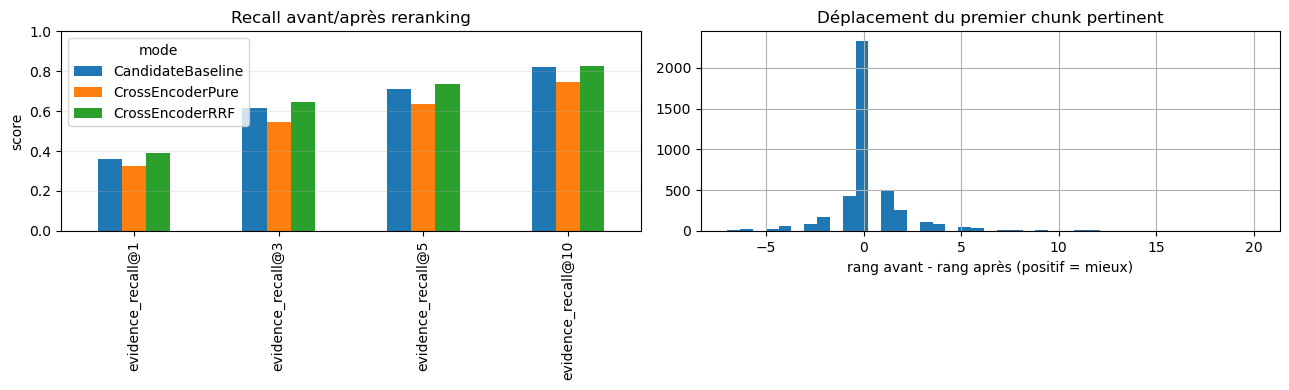

In [12]:
movement_rows = []
for example, before, after in zip(validation_examples, baseline_rankings, selected_rankings):
    relevant = set(example["strategy_ground_truth"][strategy]["relevant_chunk_ids"])
    before_rank = next((rank for rank, item in enumerate(before, 1) if item["chunk_id"] in relevant), None)
    after_rank = next((rank for rank, item in enumerate(after, 1) if item["chunk_id"] in relevant), None)
    movement_rows.append({"example_id": example["id"], "domain": example["domain"], "gated": rewrite_by_example[example["id"]]["gated"], "query": queries_by_example[example["id"]], "first_relevant_rank_before": before_rank, "first_relevant_rank_after": after_rank, "rank_gain": (before_rank - after_rank) if before_rank is not None and after_rank is not None else None})
movement_df = pd.DataFrame(movement_rows)
display(movement_df.dropna(subset=["rank_gain"]).sort_values("rank_gain", ascending=False).head(10))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_data = overall.set_index("mode")[["evidence_recall@1", "evidence_recall@3", "evidence_recall@5", "evidence_recall@10"]].T
plot_data.plot(kind="bar", ax=axes[0], ylim=(0, 1), title="Recall avant/après reranking")
axes[0].set_ylabel("score"); axes[0].grid(axis="y", alpha=.25)
movement_df["rank_gain"].dropna().clip(-20, 20).hist(bins=41, ax=axes[1])
axes[1].set_title("Déplacement du premier chunk pertinent"); axes[1].set_xlabel("rang avant - rang après (positif = mieux)")
plt.tight_layout(); plt.show()

## 7. Persistance, manifest et vérification indépendante

In [13]:
def persisted_ranking_records(rankings: list[list[dict[str, Any]]], mode: str):
    for example_id, ranking in zip(example_ids, rankings):
        yield {"schema_version": "1.0.0", "experiment_id": experiment_id, "example_id": example_id, "mode": mode, "model_id": model_config["model_id"], "query_representation": config["query_representation"]["mode"], "window_aggregation": config["passage_representation"]["windowing"]["aggregation"], "candidates": [{"chunk_id": item["chunk_id"], "rank": rank, "fusion_score": item.get("fusion_score"), "reranker_score": item.get("reranker_score"), "retrieval_rank": item["retrieval_rank"], "retrieval_score": item["retrieval_score"], "window_count": item.get("window_count"), "best_window_index": item.get("best_window_index")} for rank, item in enumerate(ranking, 1)]}

reranked_output_path = OUTPUT_ROOT / "rankings" / "validation_reranked.jsonl"
selected_output_path = OUTPUT_ROOT / "rankings" / "validation_selected.jsonl"
write_jsonl_atomic(reranked_output_path, persisted_ranking_records(reranked_rankings, "CrossEncoderPure"))
write_jsonl_atomic(selected_output_path, persisted_ranking_records(selected_rankings, selected_mode))

report_frames = {"metrics_summary.json": summary_df, "metrics_by_domain.json": domain_df, "fusion_grid.json": fusion_grid_df, "movement_audit.json": movement_df}
report_outputs = {}
for filename, frame in report_frames.items():
    path = REPORT_ROOT / filename; write_json_atomic(path, dataframe_records(frame)); report_outputs[filename] = artifact_metadata(path, len(frame))
length_path = REPORT_ROOT / "input_length_audit.json"; write_json_atomic(length_path, length_audit); report_outputs[length_path.name] = artifact_metadata(length_path)
runtime_report_path = REPORT_ROOT / "runtime_observation.json"; write_json_atomic(runtime_report_path, runtime_observation); report_outputs[runtime_report_path.name] = artifact_metadata(runtime_report_path)

manifest = {"schema_version": "1.0.0", "pipeline_stage": "cross_encoder_reranking_evaluation", "generated_at_utc": datetime.now(timezone.utc).isoformat(), "experiment_id": experiment_id, "experiment_fingerprint": experiment_fingerprint, "implementation_version": config["implementation_version"], "configuration_path": str(CONFIG_PATH.relative_to(PROJECT_ROOT)), "configuration_hash": config_hash, "inputs": {"benchmark_id": config["benchmark_id"], "validation_sha256": validation_expected["sha256"], "query_rewriting_experiment_id": config["query_rewriting_experiment_id"], "query_manifest_sha256": file_sha256(query_manifest_path), "ranking_sha256": file_sha256(ranking_path), "rewrite_sha256": file_sha256(rewrite_path), "chunking_experiment_id": config["chunking_experiment_id"], "chunks_sha256": file_sha256(chunk_path)}, "model": {**model_config, "resolved_device": device_name, "resolved_dtype": str(dtype)}, "representations": {"query": config["query_representation"], "passage": config["passage_representation"]}, "candidate_depth": candidate_depth, "selected_mode": selected_mode, "selected_fusion_parameters": selected_fusion_parameters, "accepted_for_next_stage": accepted, "performance": {"primary_metric": primary_metric, "primary_gain": primary_gain, "mrr_metric": mrr_metric, "mrr_gain": mrr_gain}, "artifacts": {"reranked_rankings": artifact_metadata(reranked_output_path, len(validation_examples)), "selected_rankings": artifact_metadata(selected_output_path, len(validation_examples)), "score_cache": {"path": str(cache_path.relative_to(PROJECT_ROOT)), "rows_for_model_configuration": len(score_by_key)}, "runtime": artifact_metadata(RUNTIME_PATH), "reports": report_outputs}, "quality": {"status": quality_status, "errors": quality_errors, "warnings": quality_warnings, "test_split_loaded": False, "score_coverage": score_coverage, "baseline_parity_differences": parity_differences, "candidate_recall_at_50_drift": candidate_recall_drift}, "decision": f"{selected_mode} selected on validation. Test remains locked; decision is provisional until the full RAG pipeline is frozen."}
manifest_path = OUTPUT_ROOT / "manifest.json"; write_json_atomic(manifest_path, manifest)
report = {**manifest, "overall_metrics": dataframe_records(overall), "slice_metrics": dataframe_records(summary_df), "runtime_observation": runtime_observation, "input_length_audit": length_audit}
report_path = REPORT_ROOT / "reranking_report.json"; write_json_atomic(report_path, report)
cache_connection.execute("PRAGMA wal_checkpoint(TRUNCATE)"); cache_connection.close()

persisted = load_json(report_path)
assert persisted["quality"]["status"] == "passed" and persisted["quality"]["test_split_loaded"] is False
assert sum(1 for _ in iter_jsonl(reranked_output_path)) == len(validation_examples)
assert sum(1 for _ in iter_jsonl(selected_output_path)) == len(validation_examples)
assert file_sha256(reranked_output_path) == persisted["artifacts"]["reranked_rankings"]["sha256"]
assert file_sha256(selected_output_path) == persisted["artifacts"]["selected_rankings"]["sha256"]
for filename, metadata in report_outputs.items(): assert file_sha256(REPORT_ROOT / filename) == metadata["sha256"]
print(f"✅ Rapport : {report_path}")
print(f"✅ Quality={quality_status}; sélection={selected_mode}; test non chargé; artefacts cohérents")

✅ Rapport : C:\Users\dhiar\OneDrive\Bureau\Project\RAG Assistant\reports\generated\multidoc2dial_v1\reranking_experiments\cross_encoder_reranking_v1_6e405e9926\reranking_report.json
✅ Quality=passed; sélection=CrossEncoderRRF; test non chargé; artefacts cohérents


## 8. Interprétation

Le reranker est un signal candidat, pas une amélioration présumée. Le notebook compare son ordre pur à une fusion RRF avec le retrieval initial. Si `CrossEncoderRRF` est sélectionné, seuls les candidats jusqu'à la profondeur retenue devront être scorés en production; sinon le pipeline conserve l'ordre Hybrid+Rewrite. La latence et la qualité déterminent ensuite si un challenger plus lourd doit être évalué.